### Evaluating Scikit-learn Models corresponding to the algorithms implemented in the first part , with:
  ## same hypermarameter values
  ## same number of most frequent and rare words and m words with the most IG(Information Gain) 

Import Libraries

In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import classification_report, precision_recall_fscore_support
from sklearn.feature_selection import mutual_info_classif
import matplotlib.pyplot as plt
from collections import Counter
import re
from bs4 import BeautifulSoup
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import BernoulliNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

Loading and Preprocessing the data

In [2]:
file_path = '/Users/pckiousis/Downloads/IMDB Dataset.csv'
imdb_data = pd.read_csv(file_path)
imdb_data['sentiment'] = imdb_data['sentiment'].map({'positive': 1, 'negative': 0})

Cleaning and treating the text like vector and counting the word frequency(number of 1 in the vector)

In [3]:
def clean_text(text):
    try:
        text = BeautifulSoup(text, "html.parser").get_text()
    except Exception:
        text = str(text)
    text = re.sub(r'[^a-zA-Z\s]', '', text).lower()
    return text

imdb_data['cleaned_review'] = imdb_data['review'].apply(clean_text)

# Subset data for faster processing
subset_size = 5000
imdb_subset = imdb_data.sample(n=subset_size, random_state=42)

# Calculate word frequencies
vectorizer_full = CountVectorizer(binary=True, stop_words='english')
X_full_counts = vectorizer_full.fit_transform(imdb_subset['cleaned_review'])
word_freq = np.asarray((X_full_counts > 0).sum(axis=0)).flatten()

/var/folders/tx/6xkjd5sj2939z8hlssc2tdhr0000gp/T/ipykernel_61726/1630828372.py:3: MarkupResemblesLocatorWarning: The input looks more like a filename than markup. You may want to open this file and pass the filehandle into Beautiful Soup.
  text = BeautifulSoup(text, "html.parser").get_text()


Removing n most frequent and k most rare words from the text 

In [4]:
n = 100
k = 100
valid_indices = np.argsort(word_freq)[k:len(word_freq) - n]
X_filtered_counts = X_full_counts[:, valid_indices]
filtered_vocab = np.array(vectorizer_full.get_feature_names_out())[valid_indices]

Selecting m words with highest IG

In [5]:
m = 1000
mutual_info = mutual_info_classif(X_filtered_counts, imdb_subset['sentiment'], discrete_features=True)
top_m_indices = np.argsort(mutual_info)[-m:]
X_final_counts = X_filtered_counts[:, top_m_indices]
final_vocab = filtered_vocab[top_m_indices]

Splitting the data into training,development and test sets

In [6]:
X_train, X_temp, y_train, y_temp = train_test_split(X_final_counts, imdb_subset['sentiment'], test_size=0.4, random_state=42)
X_dev, X_test, y_dev, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

Converting the labels into numpy arrays

In [7]:
y_train = y_train.to_numpy()
y_temp = y_temp.to_numpy()
y_dev = y_dev.to_numpy()
y_test = y_test.to_numpy()

Initializing Scikit-learn Models with Respective arguments as our Custom implementation

In [8]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, C=10.0, random_state=42), # C=10 because in default logistic regression model,C is the inverse of the regularization value(e.g in our custom implementation we used 0.1 regularization ,so C=10
    "Naive Bayes": BernoulliNB(alpha=1),
    "Random Forest": RandomForestClassifier(n_estimators=1000, max_depth=20, random_state=42),
    "MLP (Neural Network)": MLPClassifier(hidden_layer_sizes=(100,), max_iter=500, alpha=0.01, random_state=42)
}

Training and Evaluating each Model

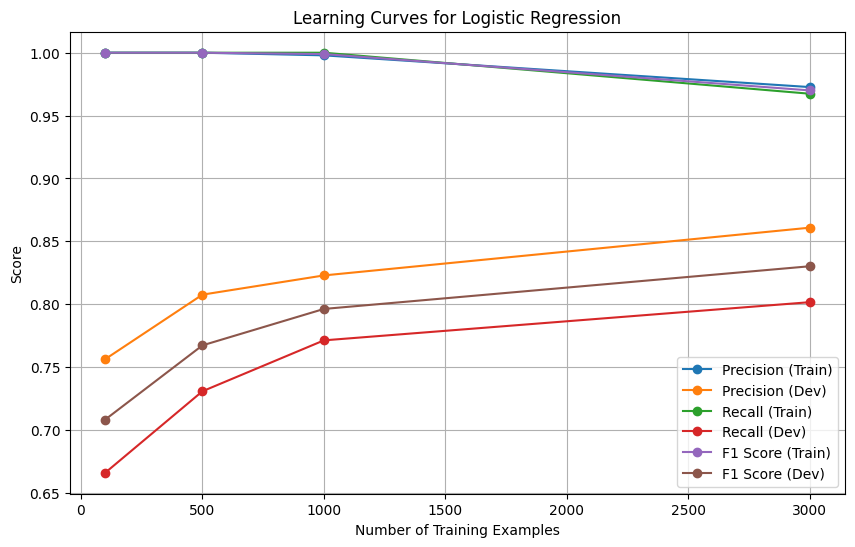

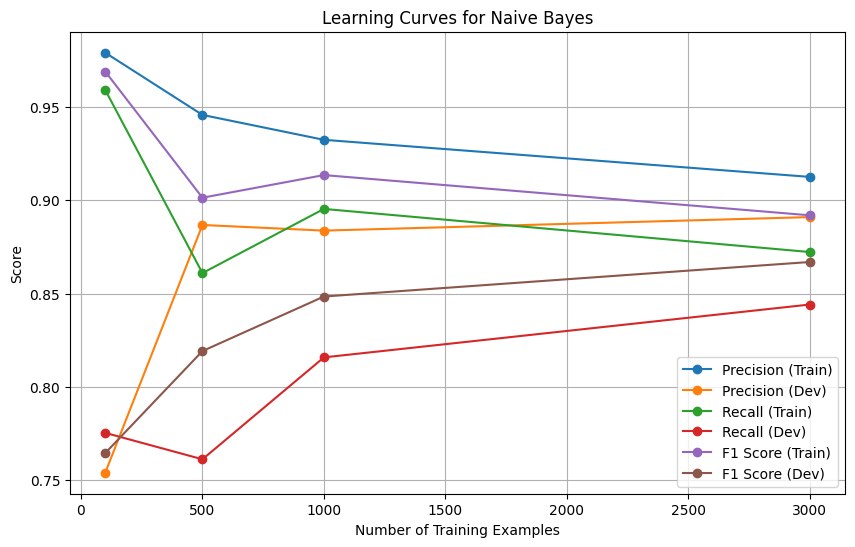

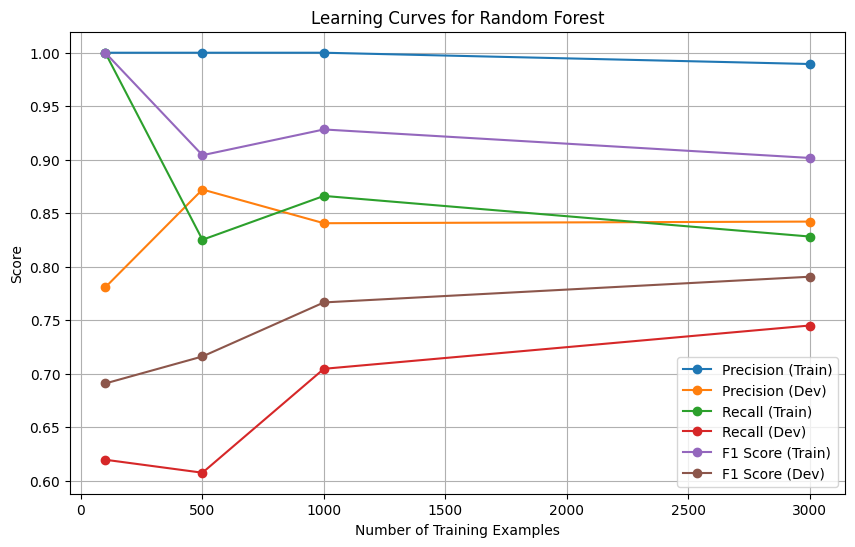

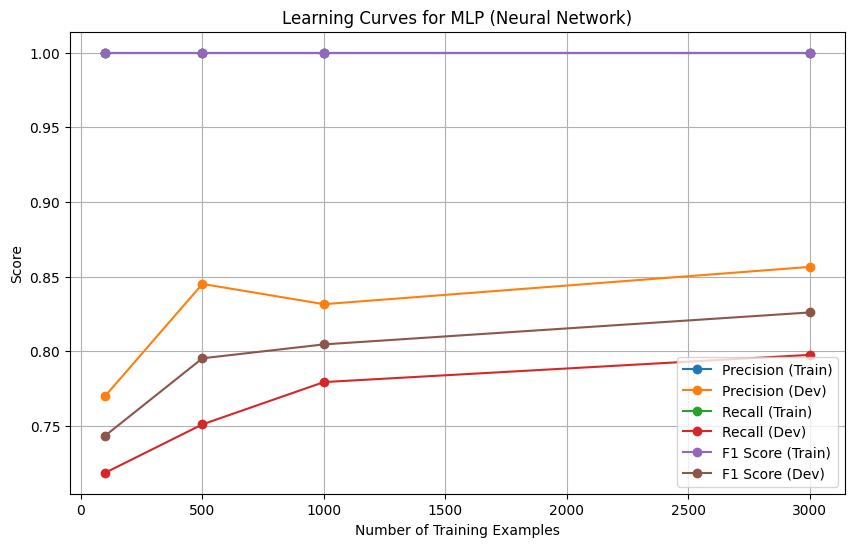

In [9]:
train_sizes = [100, 500, 1000, X_train.shape[0]]
results = {}

for model_name, model in models.items():
    precision_dev, recall_dev, f1_dev = [], [], []
    precision_train, recall_train, f1_train = [], [], []

    for size in train_sizes:
        X_train_subset = X_train[:size].toarray()
        y_train_subset = y_train[:size]

        model.fit(X_train_subset, y_train_subset)

        # Evaluate on Development Data
        y_pred_dev = model.predict(X_dev.toarray())
        precision, recall, f1, _ = precision_recall_fscore_support(y_dev, y_pred_dev, average=None, labels=[0])
        precision_dev.append(precision[0])
        recall_dev.append(recall[0])
        f1_dev.append(f1[0])

        # Evaluate on Training Data
        y_pred_train = model.predict(X_train_subset)
        precision, recall, f1, _ = precision_recall_fscore_support(y_train_subset, y_pred_train, average=None, labels=[0])
        precision_train.append(precision[0])
        recall_train.append(recall[0])
        f1_train.append(f1[0])

    results[model_name] = {
        "precision_train": precision_train,
        "recall_train": recall_train,
        "f1_train": f1_train,
        "precision_dev": precision_dev,
        "recall_dev": recall_dev,
        "f1_dev": f1_dev
    }

   
    plt.figure(figsize=(10, 6))
    plt.plot(train_sizes, precision_train, label="Precision (Train)", marker='o')
    plt.plot(train_sizes, precision_dev, label="Precision (Dev)", marker='o')
    plt.plot(train_sizes, recall_train, label="Recall (Train)", marker='o')
    plt.plot(train_sizes, recall_dev, label="Recall (Dev)", marker='o')
    plt.plot(train_sizes, f1_train, label="F1 Score (Train)", marker='o')
    plt.plot(train_sizes, f1_dev, label="F1 Score (Dev)", marker='o')
    plt.xlabel("Number of Training Examples")
    plt.ylabel("Score")
    plt.title(f"Learning Curves for {model_name}")
    plt.legend()
    plt.grid()
    plt.show()

Evaluating each Model on Test data depicting precision ,recall, micro and average scores

In [11]:
print("\nTest Data Evaluation:\n")
for model_name, model in models.items():
    model.fit(X_train.toarray(), y_train)  # Train the model on the entire training dataset
    y_pred_test = model.predict(X_test.toarray())  # Predict on test data

    # Compute precision, recall, F1 scores for each class and averages
    precision, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred_test, average=None, labels=[0, 1])
    micro_avg = precision_recall_fscore_support(y_test, y_pred_test, average='micro')
    macro_avg = precision_recall_fscore_support(y_test, y_pred_test, average='macro')

    print(f"Model: {model_name}")
    print(f"Class 0: Precision: {precision[0]:.2f}, Recall: {recall[0]:.2f}, F1: {f1[0]:.2f}")
    print(f"Class 1: Precision: {precision[1]:.2f}, Recall: {recall[1]:.2f}, F1: {f1[1]:.2f}")
    print(f"Micro Average: Precision: {micro_avg[0]:.2f}, Recall: {micro_avg[1]:.2f}, F1: {micro_avg[2]:.2f}")
    print(f"Macro Average: Precision: {macro_avg[0]:.2f}, Recall: {macro_avg[1]:.2f}, F1: {macro_avg[2]:.2f}")
    print("*" * 60)


Test Data Evaluation:

Model: Logistic Regression
Class 0: Precision: 0.88, Recall: 0.84, F1: 0.86
Class 1: Precision: 0.84, Recall: 0.87, F1: 0.86
Micro Average: Precision: 0.86, Recall: 0.86, F1: 0.86
Macro Average: Precision: 0.86, Recall: 0.86, F1: 0.86
************************************************************
Model: Naive Bayes
Class 0: Precision: 0.89, Recall: 0.86, F1: 0.88
Class 1: Precision: 0.86, Recall: 0.89, F1: 0.87
Micro Average: Precision: 0.88, Recall: 0.88, F1: 0.88
Macro Average: Precision: 0.88, Recall: 0.88, F1: 0.88
************************************************************
Model: Random Forest
Class 0: Precision: 0.84, Recall: 0.77, F1: 0.80
Class 1: Precision: 0.77, Recall: 0.85, F1: 0.81
Micro Average: Precision: 0.81, Recall: 0.81, F1: 0.81
Macro Average: Precision: 0.81, Recall: 0.81, F1: 0.81
************************************************************
Model: MLP (Neural Network)
Class 0: Precision: 0.87, Recall: 0.84, F1: 0.86
Class 1: Precision: 0.84,